# Segment a whole slide

`process_large_image` segments cells and nuclei across an image too large to
give Cellpose in one piece. It reads a `(C, Y, X)` TIFF or OME-TIFF, cuts it
into chunks, runs a **cell** model and a **nuclei** model on every chunk, and
writes the outline of every object, in whole-image pixel coordinates, to two
CSV files.

In this tutorial you will:

1. segment a synthetic 2-channel image whose cells are known, and check the counts;
2. look at the outline CSVs and overlay them on the image;
3. see what happens to cells cut by a chunk boundary;
4. segment a crop of a real 3-channel image (Sample 3: nuclei, GFAP, phalloidin).

**Runtime:** about a minute on 8 CPU cores. **Requires:** SMINT with
Cellpose 3 (`pip install "cellpose<4"`), which provides the built-in `cyto3`
and `nuclei` models used here. A GPU is used automatically when present.

**Data.** `data/synthetic_wsi.ome.tif` is made by
`python examples/make_tutorial_data.py`; the Sample 3 crop ships with the
repository. Run the notebook from `docs/tutorials/`.

**Download this notebook:** [01_segmentation.ipynb](01_segmentation.ipynb)

In [1]:
import logging
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s",
                    stream=sys.stdout, force=True)
logging.getLogger("cellpose").setLevel(logging.WARNING)   # model-loading chatter

import warnings
warnings.filterwarnings("ignore", module=r"(torch|cellpose)\.")   # library deprecation notices

from smint.segmentation import process_large_image


def composite(image, colours):
    """Percentile-normalise each channel and add them up in the given RGB colours."""
    rgb = np.zeros(image.shape[1:] + (3,))
    for channel, colour in zip(image, colours):
        lo, hi = np.percentile(channel, (1, 99.7))
        rgb += np.clip((channel - lo) / (hi - lo), 0, 1)[..., None] * np.asarray(colour)
    return np.clip(rgb, 0, 1)


def draw_outlines(ax, outlines, colour, lw=0.8):
    """Plot every object in an outline CSV (global_cell_id, x, y)."""
    for _, obj in outlines.groupby("global_cell_id"):
        ax.plot(np.append(obj.x.values, obj.x.values[0]),
                np.append(obj.y.values, obj.y.values[0]), color=colour, lw=lw)

## 1. The image

The synthetic image is 1024 × 1024 px with two channels: channel 0 is a
nuclear stain, channel 1 a cytoplasm / membrane stain. It holds 753 cells,
each with one nucleus, around two empty "vessels".

(2, 1024, 1024) uint8 - 753 cells in the truth table


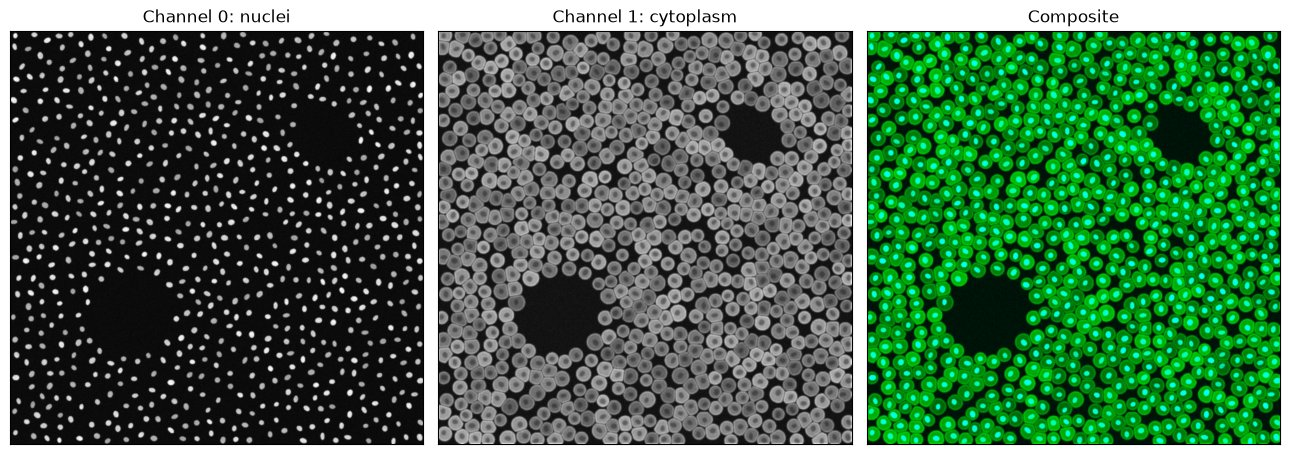

In [2]:
image = tifffile.imread("data/synthetic_wsi.ome.tif")
truth = pd.read_csv("data/synthetic_wsi_truth.csv")
print(image.shape, image.dtype, f"- {len(truth)} cells in the truth table")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(image[0], cmap="gray"); axes[0].set_title("Channel 0: nuclei")
axes[1].imshow(image[1], cmap="gray"); axes[1].set_title("Channel 1: cytoplasm")
axes[2].imshow(composite(image, [(0, 1, 1), (0, 0.8, 0)])); axes[2].set_title("Composite")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 2. Segment

Each model gets its own diameter, thresholds and channels. `channels` follows
Cellpose 3's convention, `[main, nuclear]`, **1-based**, with 0 meaning none:

- cells: `[2, 1]` — channel index 1 (cytoplasm) as the main channel, helped by
  channel index 0 (nuclei);
- nuclei: `[1, 0]` — channel index 0 alone.

SMINT applies the same convention on Cellpose 3 and Cellpose 4. The image is
processed in 512 px chunks here, so you can see four chunks on a small image;
on a real slide use 2048 px or more.

In [3]:
import os

os.makedirs("segmentation", exist_ok=True)   # create the output folder

results = process_large_image(
    image_path="data/synthetic_wsi.ome.tif",
    csv_base_path="segmentation/synthetic",   # writes segmentation/synthetic_cells.csv, _nuclei.csv
    chunk_size=(512, 512),
    cell_model_path="cyto3", cells_diameter=36,
    cells_flow_threshold=0.4, cells_cellprob_threshold=0.0, cells_channels=[2, 1],
    nuclei_model_path="nuclei", nuclei_diameter=15,
    nuclei_flow_threshold=0.4, nuclei_cellprob_threshold=0.0, nuclei_channels=[1, 0],
    visualize=False,
)

INFO: ==================================================


INFO: Starting DUAL MODEL image processing at 2026-10-26 16:14:24.829232


INFO: Input image: data/synthetic_wsi.ome.tif


INFO: Output CSV base: segmentation/synthetic


INFO: Chunk size: (512, 512)


...

INFO: Processing completed at 2026-10-26 16:15:02.613084


INFO: Total time: 37.8 seconds


INFO: Processed 4/4 chunks


INFO: Found 795 cells and 774 nuclei


INFO: ==================================================


In [4]:
{k: results[k] for k in ("cells_csv_path", "nuclei_csv_path", "total_cells", "total_nuclei")}

{'cells_csv_path': 'segmentation/synthetic_cells.csv',
 'nuclei_csv_path': 'segmentation/synthetic_nuclei.csv',
 'total_cells': 795,
 'total_nuclei': 774}

## 3. The outputs

Each CSV holds one row per outline **vertex**: `global_cell_id` numbers the
objects across the whole image, `chunk_id` names the chunk by its top-left
corner (`"y_x"`), and `x` / `y` are whole-image pixel coordinates.

In [5]:
cell_outlines = pd.read_csv(results["cells_csv_path"])
nuclei_outlines = pd.read_csv(results["nuclei_csv_path"])
cell_outlines.head()

,global_cell_id,chunk_id,x,y
0,1,0_0,30,0
1,1,0_0,31,0
2,1,0_0,31,1
3,1,0_0,32,1
4,1,0_0,32,2


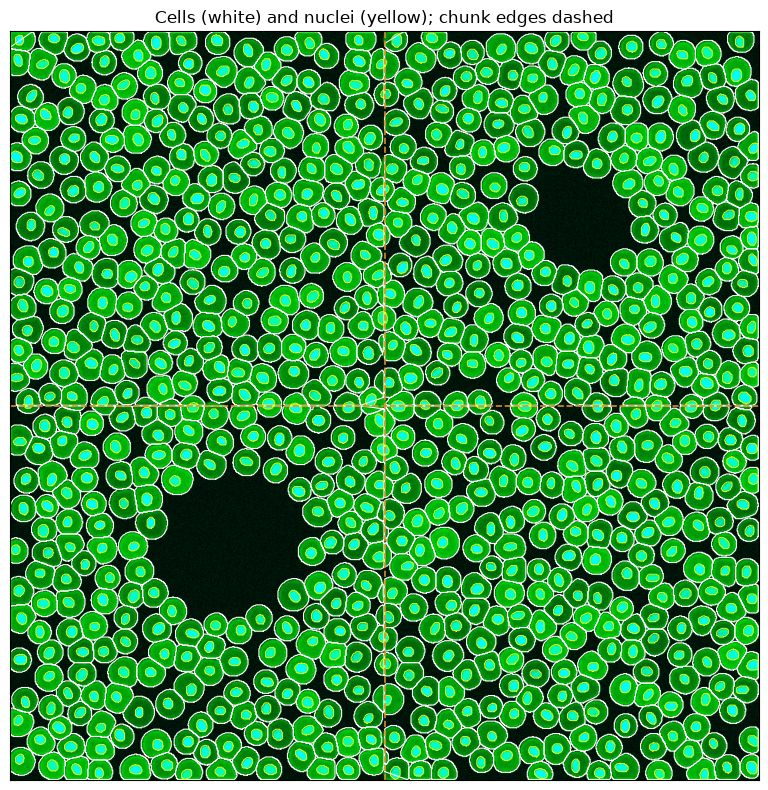

In [6]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(composite(image, [(0, 1, 1), (0, 0.8, 0)]))
draw_outlines(ax, cell_outlines, "white")
draw_outlines(ax, nuclei_outlines, "yellow", lw=0.6)
for edge in (512,):
    ax.axvline(edge, color="#dd8a2e", ls="--", lw=1.2)
    ax.axhline(edge, color="#dd8a2e", ls="--", lw=1.2)
ax.set_title("Cells (white) and nuclei (yellow); chunk edges dashed")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

The image holds 753 cells, but SMINT reports more. The extra objects sit on
the dashed chunk edges: chunks are segmented independently, so a cell that a
boundary crosses is reported once from each side, as two halves.

795 cells found, 753 in the image; 103 outlines touch a chunk edge


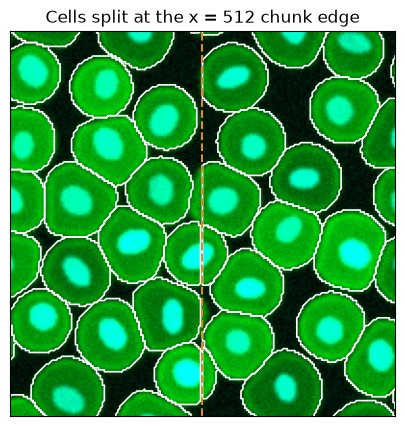

In [7]:
on_edge = (cell_outlines.groupby("global_cell_id")
           .agg(x0=("x", "min"), x1=("x", "max"), y0=("y", "min"), y1=("y", "max")))
touches = (((on_edge.x0 <= 512) & (on_edge.x1 >= 511)) | ((on_edge.y0 <= 512) & (on_edge.y1 >= 511)))
print(f"{results['total_cells']} cells found, {len(truth)} in the image; "
      f"{touches.sum()} outlines touch a chunk edge")

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(composite(image, [(0, 1, 1), (0, 0.8, 0)]))
draw_outlines(ax, cell_outlines, "white", lw=1.2)
ax.axvline(511.5, color="#dd8a2e", ls="--", lw=1.5)
ax.set(xlim=(412, 612), ylim=(300, 100), title="Cells split at the x = 512 chunk edge")
ax.set_xticks([]); ax.set_yticks([])
plt.show()

For a slide this is a small fraction of all cells, but it is avoidable:
`run_distributed_segmentation` segments overlapping tiles and **stitches**
the duplicates back into whole cells — see
[Distributed segmentation](../04_distributed_segmentation/). For a single
image that fits in one chunk, set `chunk_size` to the image size.

## 4. Real data: Sample 3

A 2048 × 2048 px region of a Sample 3 tile scan, downsampled 2× to keep the
file small, with three channels: **nuclei** (index 0), **GFAP** (index 1) and
**phalloidin** (index 2). Cells are segmented on GFAP with the nuclei as
helper channel (`[2, 1]`), nuclei on the nuclear channel (`[1, 0]`). The whole
crop fits in one chunk.

In [8]:
crop = tifffile.imread("data/sample3_crop.ome.tif")
print(crop.shape, crop.dtype)

results = process_large_image(
    image_path="data/sample3_crop.ome.tif",
    csv_base_path="segmentation/sample3",
    chunk_size=(1024, 1024),
    cell_model_path="cyto3", cells_diameter=60,
    cells_flow_threshold=0.4, cells_cellprob_threshold=0.0, cells_channels=[2, 1],
    nuclei_model_path="nuclei", nuclei_diameter=30,
    nuclei_flow_threshold=0.4, nuclei_cellprob_threshold=0.0, nuclei_channels=[1, 0],
    visualize=False,
)
print(results["total_cells"], "cells,", results["total_nuclei"], "nuclei")

(3, 1024, 1024) uint8
INFO: ==================================================


INFO: Starting DUAL MODEL image processing at 2026-10-26 16:15:05.811896


INFO: Input image: data/sample3_crop.ome.tif


INFO: Output CSV base: segmentation/sample3


INFO: Chunk size: (1024, 1024)


...

INFO: Total time: 12.2 seconds


INFO: Processed 1/1 chunks


INFO: Found 47 cells and 28 nuclei


INFO: ==================================================


47 cells, 28 nuclei


GFAP marks astrocyte processes as well as cell bodies, so a general-purpose
cell model also outlines patches of process network that hold no nucleus. A
simple rule removes them: keep only cells that contain a nucleus centroid.
(`run_distributed_segmentation` applies the same rule, with polygons, before
stitching.)

In [9]:
from matplotlib.path import Path

cells3 = pd.read_csv(results["cells_csv_path"])
nuclei3 = pd.read_csv(results["nuclei_csv_path"])
nucleus_centres = nuclei3.groupby("global_cell_id")[["x", "y"]].mean().to_numpy()
with_nucleus = [cid for cid, obj in cells3.groupby("global_cell_id")
                if Path(obj[["x", "y"]].to_numpy()).contains_points(nucleus_centres).any()]
kept = cells3[cells3.global_cell_id.isin(with_nucleus)]
print(f"{cells3.global_cell_id.nunique()} cell outlines -> {len(with_nucleus)} contain a nucleus")

47 cell outlines -> 18 contain a nucleus


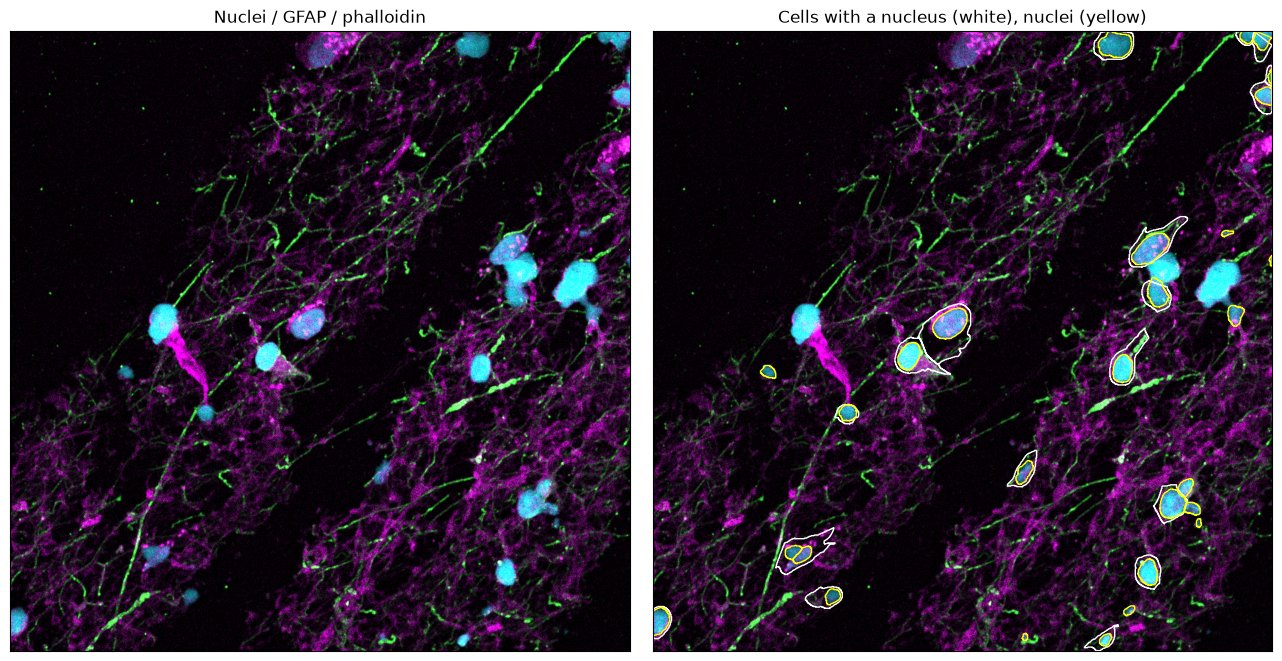

In [10]:
# nuclei cyan, GFAP green, phalloidin magenta; cells white, nuclei yellow
colours = [(0, 1, 1), (0, 1, 0), (1, 0, 1)]
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
axes[0].imshow(composite(crop, colours)); axes[0].set_title("Nuclei / GFAP / phalloidin")
axes[1].imshow(composite(crop, colours))
draw_outlines(axes[1], kept, "white", lw=1.0)
draw_outlines(axes[1], nuclei3, "yellow", lw=1.0)
axes[1].set_title("Cells with a nucleus (white), nuclei (yellow)")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

Built-in models are a starting point. For the whole-slide results in the
[worked examples](../../examples/#4-segmenting-an-image-on-one-gpu-2048-px-crop),
cells were segmented with a Cellpose-SAM model fine-tuned on this tissue, on a GPU.

## Cellpose 3 or Cellpose 4

The call is the same on both. What differs is the models:

| | Cellpose 3 | Cellpose 4 |
|---|---|---|
| Built-in models | `cyto`, `cyto2`, `cyto3`, `nuclei`, ... | `cpsam` only |
| `cell_model_path="cyto3"` | loads `cyto3` | falls back to `cpsam`, with a warning |
| Fine-tuned model | path to the model file | path to the model file |

On Cellpose 4, pass the path of a fine-tuned model as `cell_model_path` (and
`nuclei_model_path`) rather than a built-in name.

## Next steps

- [Distributed segmentation](../04_distributed_segmentation/) — overlapping
  tiles, stitching and many GPUs.
- [Segmentation guide](../../segmentation/) — every parameter of
  `process_large_image`.
- [Same-section registration](../02_same_section_registration/) — put the
  nuclei you segmented onto Xenium cells.